In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:

csv_path = "Human_Evaluation_Results.csv"

# expected columns
cols = [
    "user_id","filename","ethnicity","age_group",
    "realism","age_appropriateness","ethnic_consistency","timestamp"
]

df = pd.read_csv(
    csv_path,
    header=None,          # don't trust the first line
    names=cols,           # set correct headers
    skiprows=1,           # skip the bad first row that has the comma-joined header
    sep=",",
    quotechar='"',
    engine="python",
    on_bad_lines="skip"
)

# drop any stray Unnamed columns just in case
df = df[cols]

# tidy up
df["user_id"] = df["user_id"].str.strip()
df["filename"] = df["filename"].str.strip()
for c in ["realism","age_appropriateness","ethnic_consistency"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print(df.head())


          user_id     filename              ethnicity age_group  realism  \
0  Patrick  mburu  img0439.png        Native American     13-17        4   
1  Patrick  mburu  img0439.png        Native American     13-17        5   
2  Patrick  mburu  img0868.png               Hawaiian     26-40        4   
3  Patrick  mburu  img1213.png  Indigenous Australian     13-17        4   
4  Patrick  mburu  img0007.png                 Arabic     18-20        4   

   age_appropriateness  ethnic_consistency                   timestamp  
0                    5                   5  2025-08-04T19:02:18.212297  
1                    5                   3  2025-08-04T19:02:39.526856  
2                    5                   3  2025-08-04T19:03:29.173073  
3                    4                   3  2025-08-04T19:04:38.437746  
4                    4                   4  2025-08-04T19:04:45.210763  


In [4]:
# Count unique participants
num_users = df["user_id"].nunique()
print(f"Number of unique participants: {num_users}")

Number of unique participants: 24


In [5]:
# summary statistics
print("\nOverall Summary Stats:")
display(df[["realism", "age_appropriateness", "ethnic_consistency"]].describe())

# =========================
# 6. Average scores by ethnicity
# =========================
ethnicity_scores = df.groupby("ethnicity")[["realism", "age_appropriateness", "ethnic_consistency"]].mean().round(2)
print("\nAverage Scores by Ethnicity:")
display(ethnicity_scores.sort_values("realism", ascending=False))

# =========================
# 7. Average scores by age group
# =========================
age_group_scores = df.groupby("age_group")[["realism", "age_appropriateness", "ethnic_consistency"]].mean().round(2)
print("\nAverage Scores by Age Group:")
display(age_group_scores.sort_index())



Overall Summary Stats:


,realism,age_appropriateness,ethnic_consistency
count,630.000000,630.000000,630.000000
mean,3.319048,3.780952,3.803175
std,1.115629,0.989429,1.071078
min,1.000000,1.000000,1.000000
25%,2.000000,3.000000,3.000000
50%,3.000000,4.000000,4.000000
75%,4.000000,4.000000,5.000000
max,5.000000,5.000000,5.000000



Average Scores by Ethnicity:


,realism,age_appropriateness,ethnic_consistency
ethnicity,,,
White/European,3.86,4.07,4.43
Arabic,3.70,3.98,4.10
Native American,3.46,4.02,3.79
Brazilian,3.39,3.64,3.57
Indian,3.32,3.75,3.96
African,3.27,3.98,3.96
Indigenous Australian,3.22,3.53,3.35
Hawaiian,3.12,3.81,3.56
Black Caribbean,3.11,3.73,3.72



Average Scores by Age Group:


,realism,age_appropriateness,ethnic_consistency
age_group,,,
13-17,3.22,3.65,3.75
18-20,3.46,3.73,3.92
21-25,3.33,3.78,3.87
26-40,3.35,3.92,3.69
41plus,3.24,3.84,3.78


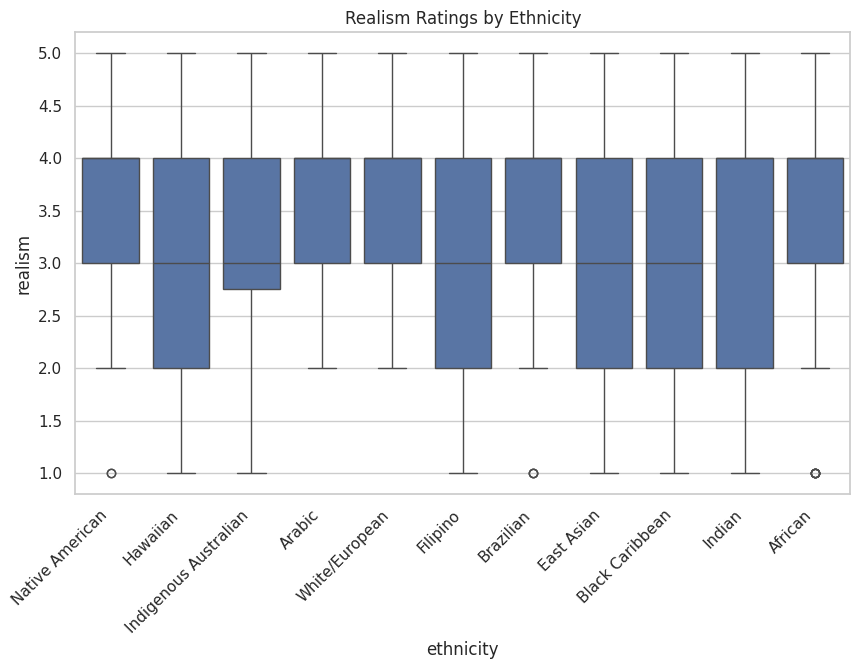

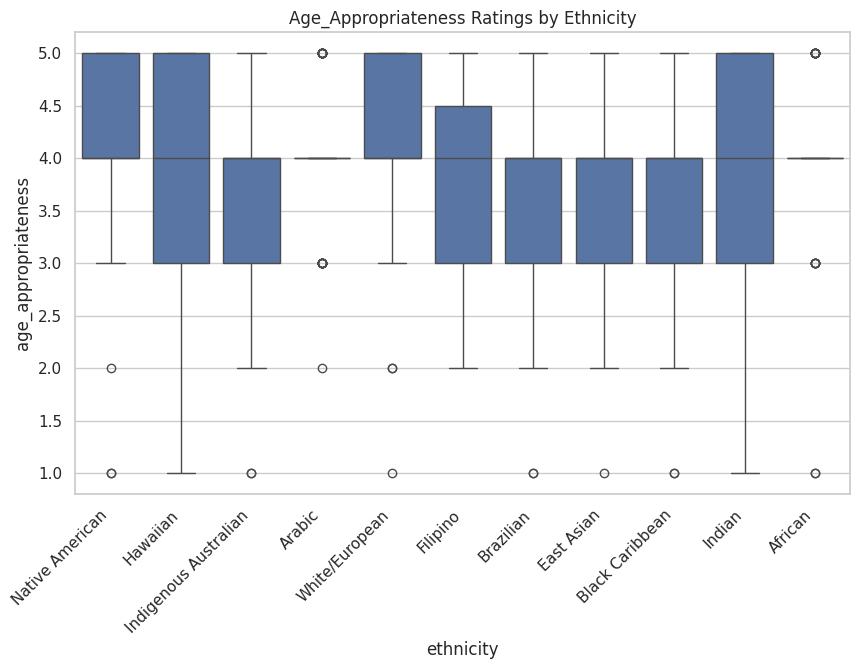

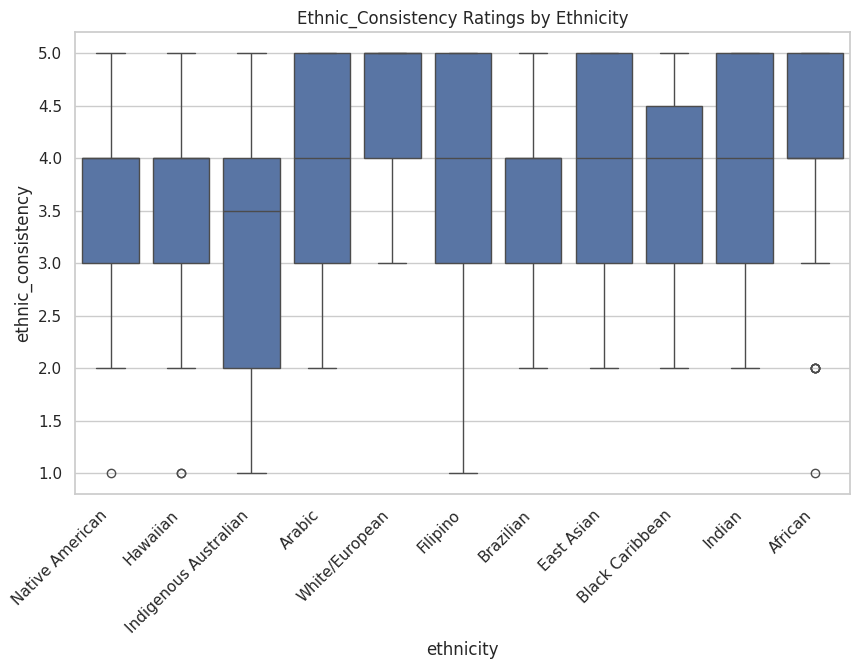

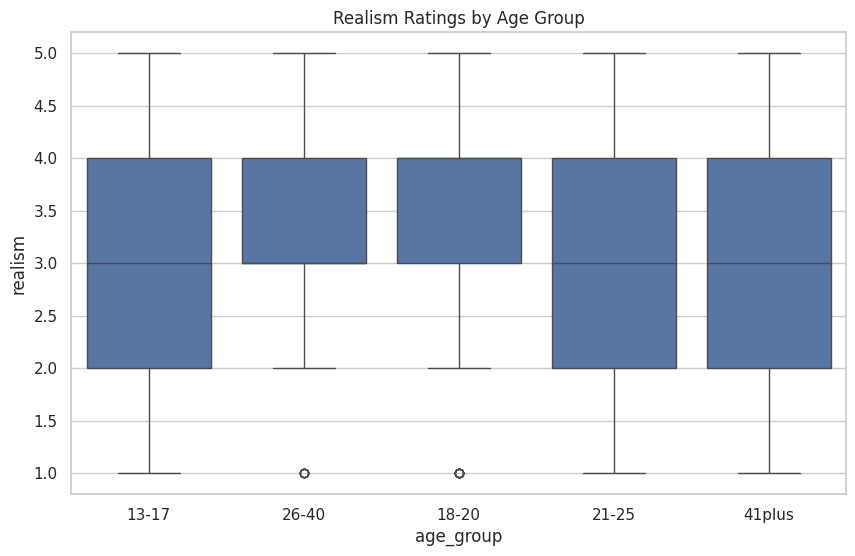

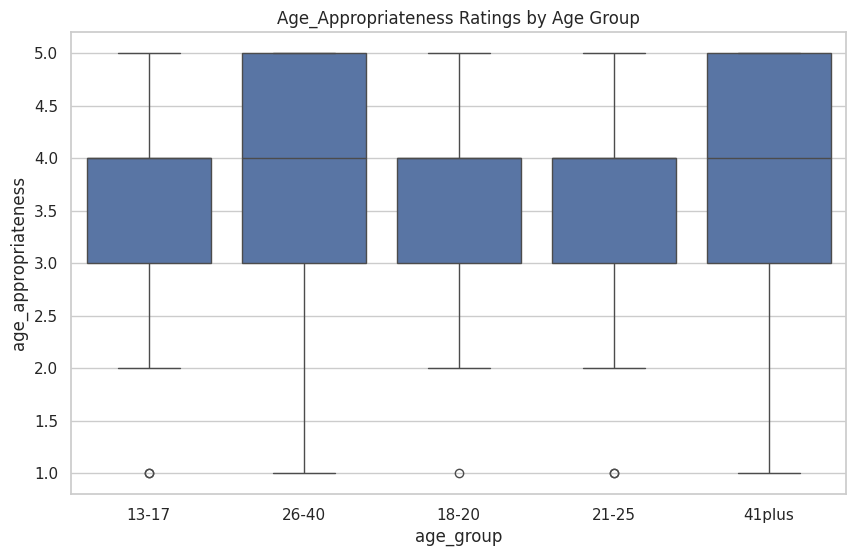

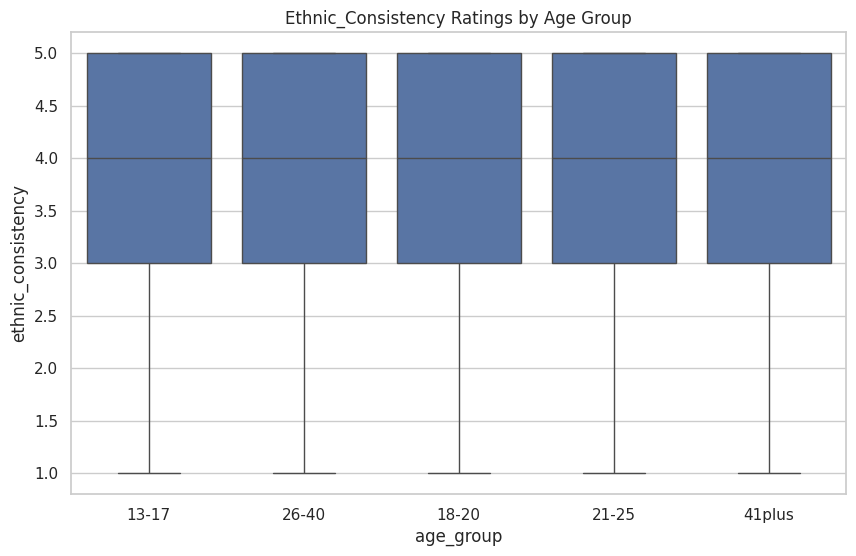


Overall Average Scores:
realism                3.32
age_appropriateness    3.78
ethnic_consistency     3.80
dtype: float64


In [6]:
# --- Boxplot per criterion by ethnicity ---
for metric in ["realism", "age_appropriateness", "ethnic_consistency"]:
    plt.figure()
    sns.boxplot(data=df, x="ethnicity", y=metric)
    plt.xticks(rotation=45, ha="right")
    plt.title(f"{metric.title()} Ratings by Ethnicity")
    plt.show()

# --- Boxplot per criterion by age group ---
for metric in ["realism", "age_appropriateness", "ethnic_consistency"]:
    plt.figure()
    sns.boxplot(data=df, x="age_group", y=metric)
    plt.title(f"{metric.title()} Ratings by Age Group")
    plt.show()

# 9. Overall averages

overall_avg = df[["realism", "age_appropriateness", "ethnic_consistency"]].mean().round(2)
print("\nOverall Average Scores:")
print(overall_avg)


In [7]:
# heatmap correlation between criteria.

# Ensure numeric columns are correctly typed
numeric_cols = ["realism", "age_appropriateness", "ethnic_consistency"]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")

print("Data loaded and cleaned:")
print(df.head())

Data loaded and cleaned:
          user_id     filename              ethnicity age_group  realism  \
0  Patrick  mburu  img0439.png        Native American     13-17        4   
1  Patrick  mburu  img0439.png        Native American     13-17        5   
2  Patrick  mburu  img0868.png               Hawaiian     26-40        4   
3  Patrick  mburu  img1213.png  Indigenous Australian     13-17        4   
4  Patrick  mburu  img0007.png                 Arabic     18-20        4   

   age_appropriateness  ethnic_consistency                   timestamp  
0                    5                   5  2025-08-04T19:02:18.212297  
1                    5                   3  2025-08-04T19:02:39.526856  
2                    5                   3  2025-08-04T19:03:29.173073  
3                    4                   3  2025-08-04T19:04:38.437746  
4                    4                   4  2025-08-04T19:04:45.210763  


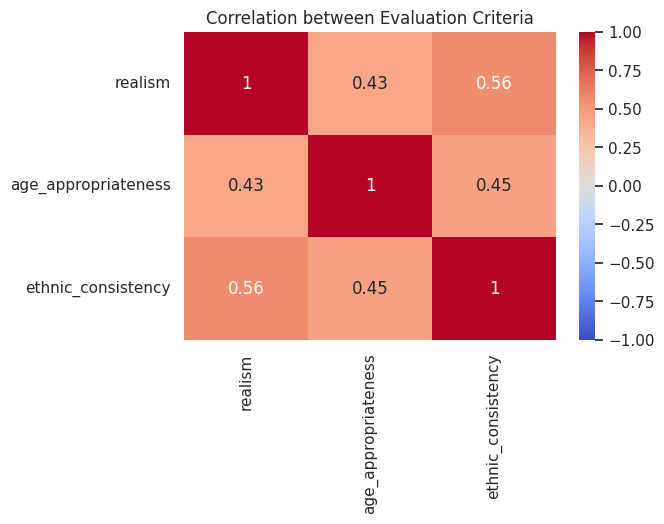

In [10]:
plt.figure(figsize=(6,4))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between Evaluation Criteria")
plt.show()


In [13]:
# Average ratings per image
avg_scores = (
    low_score_images.groupby(["filename", "ethnicity"])[numeric_cols]
    .mean()
    .reset_index()
)

# Sort and take worst 10
worst_10_unique = avg_scores.sort_values(by=numeric_cols, ascending=True).head(10)

print(worst_10_unique)


        filename        ethnicity  realism  age_appropriateness  \
85   img0848.png          African      1.0                  1.0   
83   img0822.png       East Asian      1.0                  1.0   
125  img1167.png       East Asian      1.0                  2.0   
106  img1060.png         Filipino      1.0                  2.5   
78   img0780.png         Hawaiian      1.0                  3.0   
16   img0098.png           Indian      1.0                  3.0   
24   img0147.png  Native American      1.0                  3.0   
107  img1063.png          African      1.0                  3.0   
112  img1106.png          African      1.0                  3.0   
146  img1373.png          African      1.0                  3.0   

     ethnic_consistency  
85                  1.0  
83                  3.0  
125                 2.0  
106                 1.5  
78                  1.0  
16                  2.0  
24                  2.0  
107                 2.0  
112                 2.0  
14

In [ ]:
# drop user_id and timestamp columns

df = df.drop(columns=["user_id", "timestamp"])

print(df.head())

In [9]:
# save anonymised results to CSV

# df.to_csv("evaluation_results_anonymised.csv", index=False)
# print("\nAnonymised CSV saved as 'evaluation_results_anonymised.csv'")


Anonymised CSV saved as 'evaluation_results_anonymised.csv'
